#### Librerias

In [4]:
import pandas as pd
import gzip
import networkx as nx
import pickle
from matplotlib.cm import ScalarMappable
import seaborn as sns
import matplotlib.pyplot as plt
import re
import tarfile
import numpy as np
import textwrap

#### Datos del building_id_count para un mes:

In [ ]:
f = 'graphs/building_id_count.csv'
df1 = pd.read_csv(f, nrows=1000)  # Leer solo las primeras 1000 filas

print("Muestra de datos del building_id_count para un mes:")
df1.head()

#### Datos del from_mac_hexa_to_building_id para un mes:

In [5]:
f = 'graphs/from_mac_hexa_to_building_id.csv'
df1 = pd.read_csv(f, nrows=1000)  # Leer solo las primeras 1000 filas

print("Muestra de datos del from_mac_hexa_to_building_id para un mes:")
df1.head()

Muestra de datos del from_mac_hexa_to_building_id para un mes:


,MAC_AP_hexa,building_id
0,00:35:1A:05:9A:00,891
1,00:35:1A:05:EF:D0,1318
2,00:35:1A:05:F4:C0,1052
3,00:35:1A:05:F6:60,1308
4,00:35:1A:05:F7:80,1406


## Muestra de datos del datos_APs_Abril.csv.gz y un grafo:

In [5]:
with gzip.open('../datos_ceibal/datos_resto_del_anio/datos_vecinos_Abril.csv.gz', 'rt') as f:
    df = pd.read_csv(f, nrows=1000)  # Leer solo las primeras 1000 filas

print("Muestra de datos:")
df.head(20)

Muestra de datos:


,Unnamed: 0,timestamp,WLC,MAC_AP,MAC_AP_hexa,Banda,Canal,MAC_vecino,MAC_Hexa_vecino,MAC_vecino_hexa,MAC_vecino_hexa_0,Canal_vecino,RSSI_vecino,Tx_power_vecino,Atenuacion
0,0,2018-04-01 00:09:34,WLC1,0.242.139.197.115.240,00:F2:8B:C5:73:F0,0,1.0,0.53.26.5.154.0,00 35 1A 05 9A 00,00:35:1A:05:9A:00,00:35:1A:05:9A:00,11,-82.0,13.0,-95.0
1,1,2018-04-01 00:09:34,WLC1,0.242.139.211.189.112,00:F2:8B:D3:BD:70,0,11.0,0.53.26.5.154.0,00 35 1A 05 9A 00,00:35:1A:05:9A:00,00:35:1A:05:9A:00,11,-79.0,13.0,-92.0
2,2,2018-04-01 00:09:34,WLC1,0.53.26.17.170.80,00:35:1A:11:AA:50,0,6.0,0.53.26.5.154.0,00 35 1A 05 9A 00,00:35:1A:05:9A:00,00:35:1A:05:9A:00,11,-42.0,13.0,-55.0
3,3,2018-04-01 00:09:34,WLC1,24.139.157.125.124.80,18:8B:9D:7D:7C:50,0,1.0,0.53.26.5.154.0,00 35 1A 05 9A 00,00:35:1A:05:9A:00,00:35:1A:05:9A:00,11,-54.0,13.0,-67.0
4,4,2018-04-01 00:09:34,WLC1,24.139.157.125.138.240,18:8B:9D:7D:8A:F0,0,6.0,0.53.26.5.154.0,00 35 1A 05 9A 00,00:35:1A:05:9A:00,00:35:1A:05:9A:00,11,-67.0,13.0,-80.0
5,5,2018-04-01 00:09:34,WLC1,24.139.157.131.60.0,18:8B:9D:83:3C:00,0,6.0,0.53.26.5.154.0,00 35 1A 05 9A 00,00:35:1A:05:9A:00,00:35:1A:05:9A:00,11,-91.0,13.0,-104.0
6,6,2018-04-01 00:09:34,WLC1,24.139.157.98.65.128,18:8B:9D:62:41:80,0,1.0,0.53.26.5.154.0,00 35 1A 05 9A 00,00:35:1A:05:9A:00,00:35:1A:05:9A:00,11,-89.0,13.0,-102.0
7,7,2018-04-01 00:09:34,WLC1,28.106.122.114.107.224,1C:6A:7A:72:6B:E0,0,11.0,0.53.26.5.154.0,00 35 1A 05 9A 00,00:35:1A:05:9A:00,00:35:1A:05:9A:00,11,-85.0,13.0,-98.0
8,8,2018-04-01 00:09:34,WLC1,28.106.122.157.183.0,1C:6A:7A:9D:B7:00,0,11.0,0.53.26.5.154.0,00 35 1A 05 9A 00,00:35:1A:05:9A:00,00:35:1A:05:9A:00,11,-86.0,13.0,-99.0
9,9,2018-04-01 00:09:34,WLC1,28.106.122.181.186.16,1C:6A:7A:B5:BA:10,0,1.0,0.53.26.5.154.0,00 35 1A 05 9A 00,00:35:1A:05:9A:00,00:35:1A:05:9A:00,11,-87.0,13.0,-100.0


## 2. Distribución del Tamaño de las Redes

Tenemos una muestra muy grande (1.424 edificios) con una variabilidad de hasta 33 puntos de acceso (APs).

# Comparativa densidad del grafo 856 en diferentes bandas

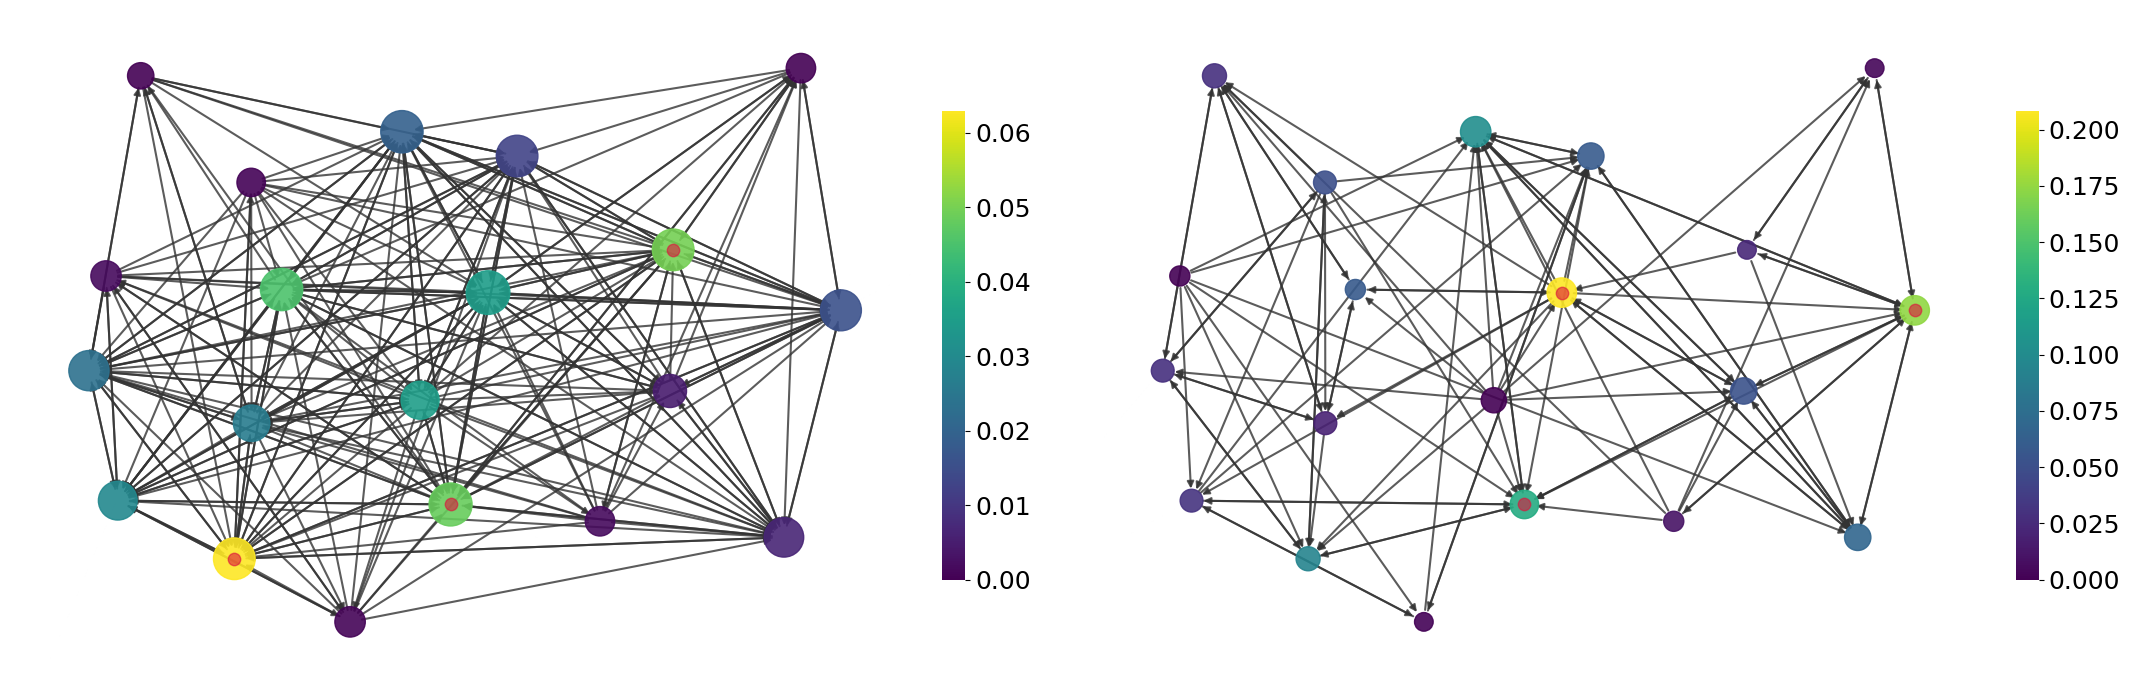

In [3]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
import pickle

# 1. Cargar ambos grafos
with open('graphs/2_4_856/list_2_4_graphs_856_marzo.pkl', 'rb') as f:
    G_24 = pickle.load(f)[0]
with open('graphs/5_856/list_5_graphs_856_marzo.pkl', 'rb') as f:
    G_5 = pickle.load(f)[0]

# --- CAMBIO CLAVE: Calcular el layout una sola vez ---
# Usamos G_24 como referencia para fijar las posiciones de los nodos
pos = nx.spring_layout(G_24, k=0.2, seed=42, iterations=50)

# 2. Configurar la figura
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 7))
graphs = [(G_24, ax1, "2.4GHz"), (G_5, ax2, "5GHz")]

# 3. Iterar para dibujar
for G, ax, band in graphs:
    # Calcular métricas
    degree = dict(G.degree())
    betweenness = nx.betweenness_centrality(G)
    
    # Configurar colores
    cmap = plt.cm.viridis
    node_colors = [betweenness[n] for n in G.nodes()]
    norm = plt.Normalize(vmin=min(node_colors) if node_colors else 0, 
                         vmax=max(node_colors) if node_colors else 1)

    # Dibujar enlaces (usando el 'pos' fijo)
    nx.draw_networkx_edges(G, pos, width=1.5, alpha=0.8, edge_color='#333333', ax=ax)


    # Dibujar nodos (usando el 'pos' fijo)
    nodes = nx.draw_networkx_nodes(
        G, pos,
        node_size=[v * 30 for v in degree.values()],
        node_color=node_colors,
        cmap=cmap,
        alpha=0.9,
        ax=ax
    )

    # Destacar top 3 nodos críticos
    top_nodes = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:3]
    nx.draw_networkx_nodes(G, pos, nodelist=[n[0] for n in top_nodes], 
                           node_size=80, node_color='crimson', alpha=0.6, ax=ax)

    # Barra de color individual
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, shrink=0.7, pad=0.02)
    cbar.outline.set_visible(False)
    
    # ------------------ NUEVO CAMBIO APLICADO ------------------
    # Aumentar el tamaño de los números (ticks) en la barra de color
    cbar.ax.tick_params(labelsize=18) 
    # -----------------------------------------------------------

    # # Título e info
    # ax.set_title(f"Nodos: {len(G.nodes())} | Enlaces: {len(G.edges())}",
    #              fontsize=23, fontweight='bold', pad=20)
    
    ax.axis('off')

plt.subplots_adjust(wspace=0.1)
plt.tight_layout()
plt.savefig('./graficas/problema1_topologías.pdf', dpi=300, bbox_inches='tight')
plt.show()



# Histograma de cantidad de aps por edificio

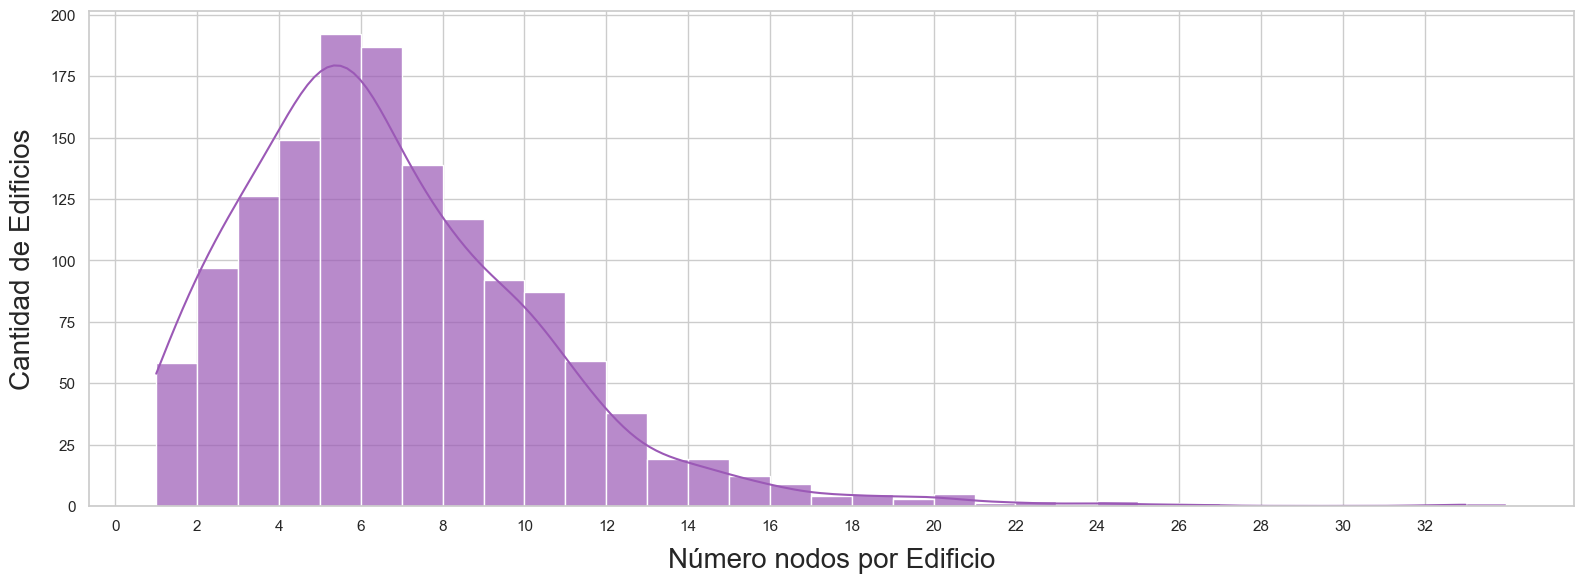

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar los datos
df_counts = pd.read_csv('graphs/building_id_count.csv')
df_counts['num_aps'] = df_counts['cantidad'].astype(str).str.extract('(\d+)').astype(int)

# 2. Configuración estética
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 6))

# 3. Crear el histograma
ax = sns.histplot(df_counts['num_aps'], bins=range(1, df_counts['num_aps'].max() + 2), 
                  kde=True, color='#9B59B6', edgecolor='white', alpha=0.7)

# 4. Títulos y etiquetas
# plt.title('Distribución de Heterogeneidad: Tamaño de las Redes', fontsize=20, fontweight='bold', pad=25, color='#333333')
plt.xlabel('Número nodos por Edificio', fontsize=20, labelpad=10)
plt.ylabel('Cantidad de Edificios', fontsize=20, labelpad=10)
plt.xticks(range(0, df_counts['num_aps'].max() + 1, 2))

# # 5. Información clave en la "Cajita" (Summary Box)
# max_aps = df_counts['num_aps'].max()
# num_buildings = len(df_counts)

# stats_text = (
#     f" RESUMEN DEL DATASET\n"
#     f"───────────────────\n"
#     f"Total Edificios: {num_buildings}\n"
#     # f"Máximo de APs:  {max_aps}\n"
#     f"Variabilidad:   1 - {max_aps} APs"
# )

# # Colocamos la cajita en la parte superior derecha
# plt.text(0.97, 0.85, stats_text, 
#          transform=ax.transAxes, fontsize=13, fontweight='bold', family='monospace',
#          verticalalignment='top', horizontalalignment='right', 
#          bbox=dict(boxstyle='round,pad=0.8', facecolor='#F8F9FA', edgecolor='#4A90E2', linewidth=2, alpha=0.9))

# # 6. Anotación visual para el máximo
# plt.annotate(f'Punto Crítico de Escala: {max_aps} APs', xy=(max_aps, 2), xytext=(max_aps-8, 60),
#              arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=8),
#              fontsize=12, fontweight='bold', color='#D63031')

plt.tight_layout()
plt.savefig('./graficas/problema1_distribucion.pdf', dpi=300, bbox_inches='tight')
plt.show()


In [9]:
import pandas as pd

# 1. Cargar y procesar (como en tu código original)
df_counts = pd.read_csv('graphs/building_id_count.csv')
df_counts['num_aps'] = df_counts['cantidad'].astype(str).str.extract('(\d+)').astype(int)

# 2. Calcular estadísticas descriptivas
stats = df_counts['num_aps'].describe()
moda = df_counts['num_aps'].mode()[0]
skewness = df_counts['num_aps'].skew() # Asimetría
total_buildings = len(df_counts)

# 3. Mostrar reporte formateado
print("="*40)
print("   ESTADÍSTICAS DE HETEROGENEIDAD (APs)")
print("="*40)
print(f"Total de Edificios:     {total_buildings}")
print(f"Media (Promedio):       {stats['mean']:.2f} APs")
print(f"Mediana (50%):          {stats['50%']:.1f} APs")
print(f"Moda (Más frecuente):   {moda} APs")
print(f"Desviación Estándar:    {stats['std']:.2f}")
print(f"Rango de Tamaño:        {stats['min']:.0f} - {stats['max']:.0f} APs")
print("-"*40)
print(f"Cuartil 25% (Peques):   {stats['25%']:.1f} APs")
print(f"Cuartil 75% (Grandes):  {stats['75%']:.1f} APs")
print(f"Asimetría (Skewness):   {skewness:.2f}")

# Interpretación rápida
if skewness > 0:
    print("\n💡 Interpretación: El dataset está sesgado a la derecha.")
    print("   La mayoría de los edificios tienen pocas APs,")
    print("   pero hay unos pocos 'gigantes' que suben la media.")


   ESTADÍSTICAS DE HETEROGENEIDAD (APs)
Total de Edificios:     1424
Media (Promedio):       6.56 APs
Mediana (50%):          6.0 APs
Moda (Más frecuente):   5 APs
Desviación Estándar:    3.69
Rango de Tamaño:        1 - 33 APs
----------------------------------------
Cuartil 25% (Peques):   4.0 APs
Cuartil 75% (Grandes):  9.0 APs
Asimetría (Skewness):   1.30

💡 Interpretación: El dataset está sesgado a la derecha.
   La mayoría de los edificios tienen pocas APs,
   pero hay unos pocos 'gigantes' que suben la media.


# HeatMap de la matriz de canal para explicar las asimetrías

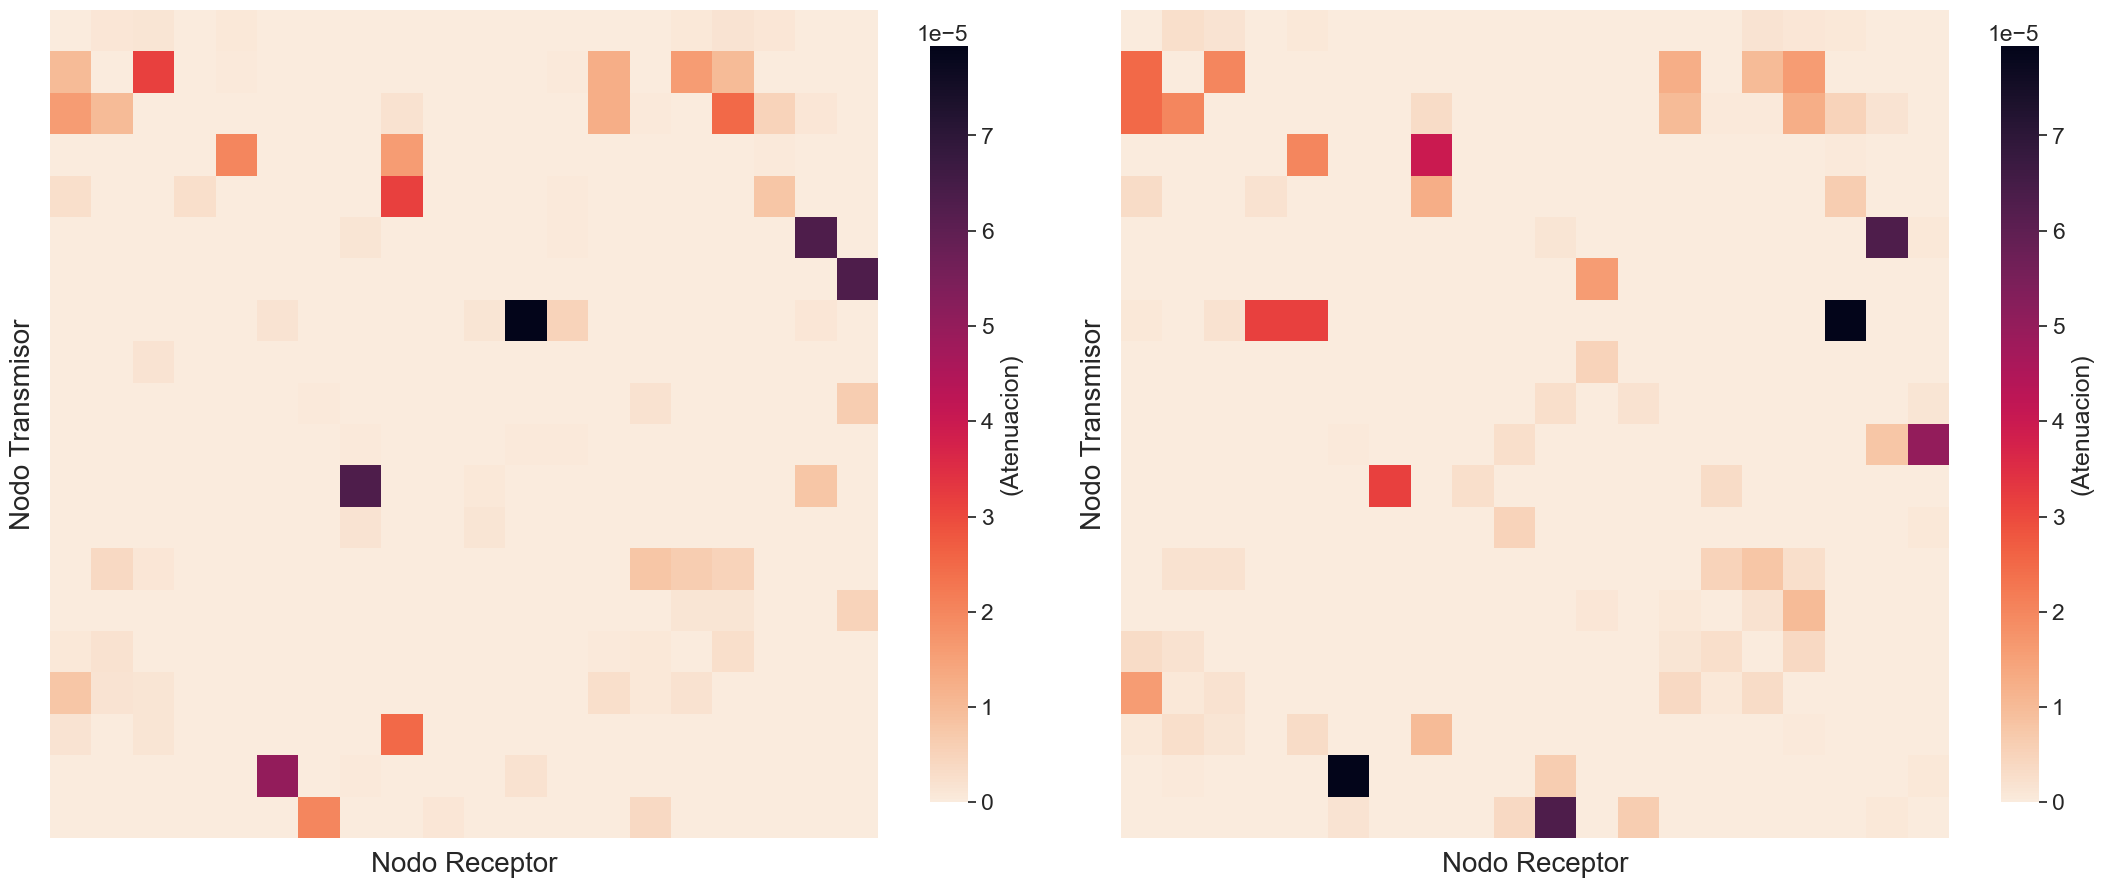

Variación media entre Marzo y Julio: 0.0000 dB


In [9]:
import networkx as nx
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pickle

# 1. Cargar grafos de dos meses distintos
def load_graph(month, index=190):
    path = f'graphs/2_4_856/list_2_4_graphs_856_{month}.pkl'
    with open(path, 'rb') as f:
        graph_list = pickle.load(f)
        return graph_list[index]

G_marzo = load_graph('marzo')
G_julio = load_graph('julio')

# 2. Identificar el atributo de peso Atenuación
first_edge = list(G_marzo.edges(data=True))[0]
target_attr = 'weight'
for attr in first_edge[2].keys():
    if isinstance(first_edge[2][attr], (int, float, np.number)):
        target_attr = attr
        break

# 3. Extraer matrices
H_marzo = nx.to_numpy_array(G_marzo, weight=target_attr)
H_julio = nx.to_numpy_array(G_julio, weight=target_attr)

# 4. Definir escala común para comparar
v_min = min(H_marzo.min(), H_julio.min())
v_max = max(H_marzo.max(), H_julio.max())

# 5. Visualización en Subplots
fig, axes = plt.subplots(1, 2, figsize=(22, 10))

# CAMBIO: Usar font_scale para subir la base de todos los textos
sns.set_theme(style="white", font_scale=1.5)

# Opciones compartidas para la barra de calor
# xticklabels=False, yticklabels=False evita la "mancha" negra de números amontonados
heatmap_kws = {
    'cmap': 'rocket_r',
    'square': True,
    'vmin': v_min, 
    'vmax': v_max,
    'xticklabels': False, # Ocultamos los numeritos de las columnas
    'yticklabels': False, # Ocultamos los numeritos de las filas
    'cbar_kws': {
        'label': f'({target_attr})',
        'shrink': 0.8  # Achica la barra de color un 20% para que no sobrepase el cuadro
    }
}

# Plot Marzo
sns.heatmap(H_marzo, ax=axes[0], **heatmap_kws)
# CAMBIO: Aumentar el fontsize de los títulos individuales
# axes[0].set_title('Matriz de Canal: Marzo', fontsize=22, fontweight='bold', pad=15)

# Plot Julio
sns.heatmap(H_julio, ax=axes[1], **heatmap_kws)
# axes[1].set_title('Matriz de Canal: Julio', fontsize=22, fontweight='bold', pad=15)

# Estética general
for ax in axes:
    # CAMBIO: Aumentar el tamaño de las etiquetas de los ejes
    ax.set_xlabel('Nodo Receptor', fontsize=20, labelpad=10)
    ax.set_ylabel('Nodo Transmisor', fontsize=20, labelpad=10)

# # Aumentar un poco más el tamaño del título global
# plt.suptitle(f'Comparativa Estacional - Edificio 856 ({len(G_marzo.nodes())} APs)', 
#              fontsize=28, fontweight='bold', y=1.02)

# Ajustar el layout para que nada se corte
plt.tight_layout()

plt.savefig('./graficas/problema1_heatmap.pdf', dpi=300, bbox_inches='tight')

plt.show()

# 6. Cálculo de diferencia
diff = np.abs(H_marzo - H_julio).mean()
print(f"Variación media entre Marzo y Julio: {diff:.4f} dB")



# RSSI variable en una semana

Cargando archivos...


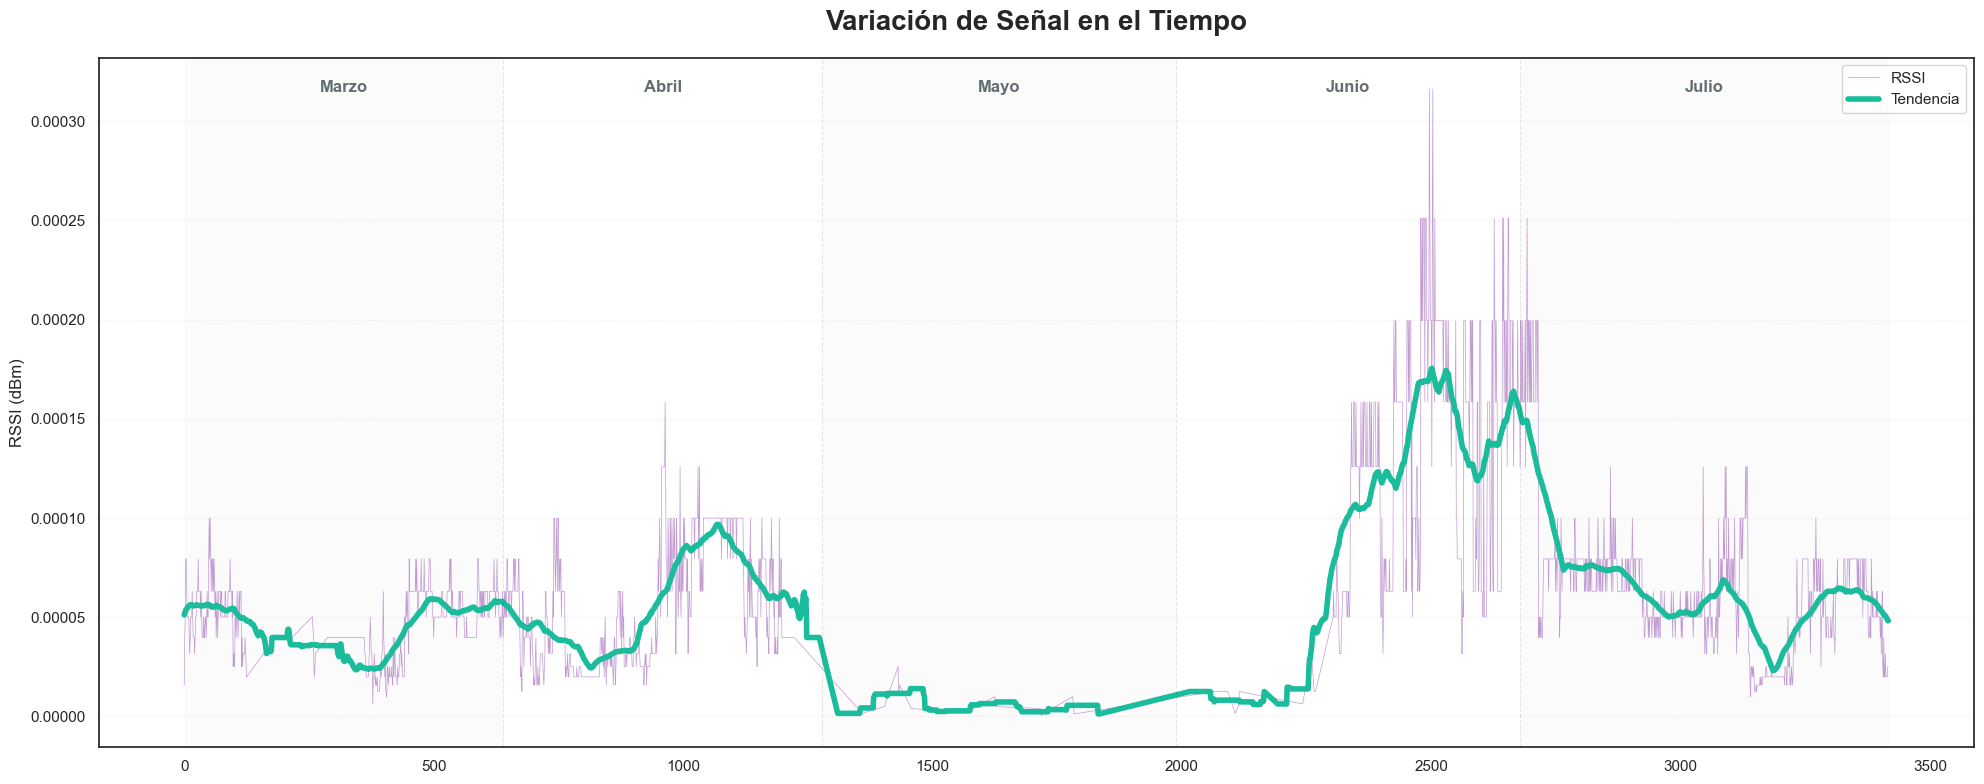

In [19]:
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Cargar datos
months = ['marzo', 'abril', 'mayo', 'junio', 'julio']
graph_list = []
month_separators = []
current_offset = 0

print("Cargando archivos...")
for m in months:
    file_path = f'graphs/2_4_856/list_2_4_graphs_856_{m}.pkl'
    try:
        with open(file_path, 'rb') as f:
            m_list = pickle.load(f)
            graph_list.extend(m_list)
            month_separators.append((current_offset, m.capitalize(), len(m_list)))
            current_offset += len(m_list)
    except FileNotFoundError:
        print(f"Advertencia: No se encontró el archivo para {m}")

# 2. Búsqueda robusta del enlace
all_unique_edges = set()
for G in graph_list:
    all_unique_edges.update(G.edges())

def find_best_link(min_presence, min_rssi):
    stats = {}
    for u, v in all_unique_edges:
        monthly_means = []
        offset = 0
        presence = 0
        for _, _, length in month_separators:
            m_values = [next((val for val in G.get_edge_data(u, v).values() if isinstance(val, (int, float))), np.nan) 
                        for G in graph_list[offset : offset + length] if G.has_edge(u, v)]
            
            if len(m_values) > length * 0.05: # Bajamos al 5% de presencia mínima
                m_mean = np.nanmean(m_values)
                monthly_means.append(m_mean)
                presence += 1
            else:
                monthly_means.append(np.nan)
            offset += length

        if presence >= min_presence and np.nanmean(monthly_means) > min_rssi:
            jump = np.nanmax(monthly_means) - np.nanmin(monthly_means)
            stats[(u, v)] = {'jump': jump, 'means': monthly_means}
    return stats

# Intentar con criterio estricto, si no, bajar exigencia
link_jump_stats = find_best_link(min_presence=4, min_rssi=-85)
if not link_jump_stats:
    print("No se encontró con 4 meses, intentando con 3...")
    link_jump_stats = find_best_link(min_presence=3, min_rssi=-90)

if not link_jump_stats:
    print("ERROR: No se encontró ningún enlace con datos suficientes en este periodo.")
else:
    # 3. Elegir el mejor
    best_edge = max(link_jump_stats, key=lambda k: link_jump_stats[k]['jump'])
    u, v = best_edge
    total_jump = link_jump_stats[best_edge]['jump']

    # 4. Preparar serie
    full_series = []
    for G in graph_list:
        val = np.nan
        if G.has_edge(u, v):
            data = G.get_edge_data(u, v)
            val = next((v for v in data.values() if isinstance(v, (int, float))), np.nan)
        full_series.append(val)

    series = pd.Series(full_series)
    moving_avg = series.rolling(window=100, center=True, min_periods=1).mean().interpolate()
    raw_interpolated = series.interpolate(method='linear')

    # 6. Graficar
    plt.figure(figsize=(20, 8))
    sns.set_theme(style="white")
    
    plt.plot(raw_interpolated, color='#9B59B6', linewidth=0.5, alpha=0.6, label='RSSI')
    plt.plot(moving_avg, color='#1ABC9C', linewidth=4, label='Tendencia')

    # Ajustar límites antes de poner los textos
    y_min, y_max = plt.gca().get_ylim()
    margin = (y_max - y_min) * 0.05
    
    colors = ['#f8f9fa', '#ffffff']
    for i, (pos, name, length) in enumerate(month_separators):
        plt.axvspan(pos, pos + length, facecolor=colors[i % 2], alpha=0.5, zorder=0)
        if pos > 0:
            plt.axvline(x=pos, color='black', linestyle='--', linewidth=0.8, alpha=0.1)
        plt.text(pos + length/2, y_max - margin, name, color='#636e72', fontsize=12, fontweight='bold', ha='center')

    plt.title(f'Variación de Señal en el Tiempo', fontsize=20, fontweight='bold', pad=20)
    plt.ylabel('RSSI (dBm)', fontsize=12)
    plt.grid(axis='y', linestyle=':', alpha=0.3)
    
    # info_text = f"Salto detectado: {total_jump:.1f} dB\nEnlace: {u} ↔ {v}"
    # plt.gca().annotate(info_text, xy=(0.01, 0.05), xycoords='axes fraction',
    #                    fontsize=12, fontweight='bold', bbox=dict(boxstyle='round', fc='white', ec='#e17055', alpha=0.9))

    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()


# Análisis por banda 

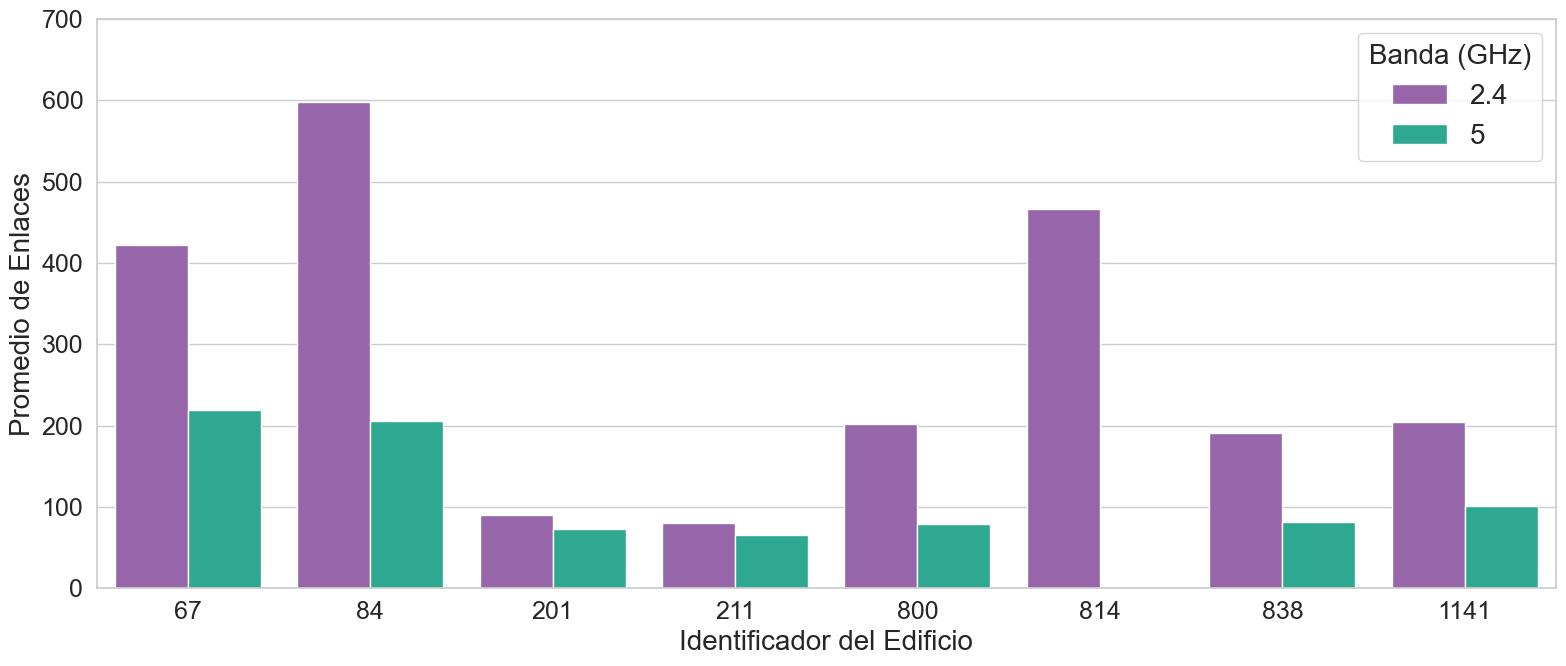

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import os

# 1. Configuración
buildings = [84, 814, 67, 800, 838, 1141, 201, 211]
bands = ['2_4', '5']
results = []
custom_colors = ["#9B59B6", "#1ABC9C"]


# 2. Recolección de datos desde los archivos .pkl
for b_id in buildings:
    for band in bands:
        # Construir la ruta al archivo de Abril
        path = f'graphs/{band}_{b_id}/list_{band}_graphs_{b_id}_marzo.pkl'
        
        if os.path.exists(path):
            with open(path, 'rb') as f:
                graphs = pickle.load(f)
            
            # Calcular el promedio de enlaces (edges) por grafo
            if len(graphs) > 0:
                avg_edges = sum(len(g.edges()) for g in graphs) / len(graphs)
                results.append({
                    'Edificio': b_id,
                    'Banda': band.replace('_', '.'), # Visualización: 2.4 en vez de 2_4
                    'Promedio_Enlaces': avg_edges,
                    'Label': f"ID {b_id}"
                })

# Convertir a DataFrame
df_results = pd.DataFrame(results)

# 3. Visualización
plt.figure(figsize=(16, 7))

# Usamos font_scale=1.5 para agrandar todos los estilos base en proporción
sns.set_theme(style="whitegrid", font_scale=1.5)

# Gráfico de barras comparando bandas por edificio
ax = sns.barplot(data=df_results, x='Edificio', y='Promedio_Enlaces', hue='Banda', palette=custom_colors)

# Estética
# plt.title('Promedio de Enlaces por Grafo (Marzo)', fontsize=26, fontweight='bold', pad=20)
plt.xlabel('Identificador del Edificio', fontsize=20)
plt.ylabel('Promedio de Enlaces', fontsize=20)

plt.legend(title='Banda (GHz)', loc='upper right', fontsize=20, title_fontsize=20)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)

# ------------- NUEVO CAMBIO APLICADO -------------
# Forzamos que el eje Y vaya desde 0 hasta 700
plt.ylim(0, 700)
# -------------------------------------------------

# # Añadir los valores exactos sobre las barras
# for p in ax.patches:
#     if p.get_height() > 0:
#         ax.annotate(f'{p.get_height():.1f}', 
#                     (p.get_x() + p.get_width() / 2., p.get_height()), 
#                     ha='center', va='center', fontsize=20, fontweight='bold',
#                     xytext=(0, 10), textcoords='offset points')

plt.tight_layout()
plt.savefig('./graficas/problema1_numero_de_enlaces.pdf', dpi=300, bbox_inches='tight')
plt.show()


# Exploración con nuevos datos de Ceibal:

In [ ]:
import tarfile

archivo_tgz = '../datos_ceibal/datos_ceibal_clientes/RSSI_WLCs_2018-07-27_11_05.tgz'

with tarfile.open(archivo_tgz, 'r:gz') as tar:
    nombres_archivos = tar.getnames()

    for nombre in nombres_archivos:
        miembro = tar.getmember(nombre)
        f = tar.extractfile(miembro)
        if f is None:
            continue

        print(f'\nArchivo: {nombre}')
        for i, linea in enumerate(f):
            if i >= 3:
                break
            print(linea.decode('utf-8').strip())


Archivo: RSSI_WLCs/datos_ASOCIACION_WLC1.txt
SNMPv2-SMI::enterprises.14179.2.1.4.1.4.0.0.6.109.6.33 = Hex-STRING: 1C 6A 7A B5 85 E0
SNMPv2-SMI::enterprises.14179.2.1.4.1.4.0.0.6.109.44.237 = Hex-STRING: 18 8B 9D 83 2D D0
SNMPv2-SMI::enterprises.14179.2.1.4.1.4.0.0.6.174.241.178 = Hex-STRING: 18 8B 9D 6E A1 C0

Archivo: RSSI_WLCs/datos_ASOCIACION_WLC3.txt
SNMPv2-SMI::enterprises.14179.2.1.4.1.4.0.0.6.108.193.34 = Hex-STRING: 00 F2 8B E9 5F E0
SNMPv2-SMI::enterprises.14179.2.1.4.1.4.0.0.6.108.212.112 = Hex-STRING: 28 6F 7F C9 D5 80
SNMPv2-SMI::enterprises.14179.2.1.4.1.4.0.0.6.108.244.236 = Hex-STRING: 1C 6A 7A EB AF 70

Archivo: RSSI_WLCs/datos_RSSI_WLC1.txt
SNMPv2-SMI::enterprises.14179.2.1.11.1.5.0.0.6.109.6.33.24.139.157.86.96.80.0.0 = INTEGER: -87
SNMPv2-SMI::enterprises.14179.2.1.11.1.5.0.0.6.109.6.33.24.139.157.86.96.80.0.1 = INTEGER: -78
SNMPv2-SMI::enterprises.14179.2.1.11.1.5.0.0.6.109.6.33.24.139.157.131.37.128.0.0 = INTEGER: -92

Archivo: RSSI_WLCs/datos_RSSI_WLC3.txt
SNMPv2

### 🧩 Estructura de los datos

Los archivos contienen líneas con información SNMP (Simple Network Management Protocol) en formato de texto plano. Cada línea representa un valor de una variable SNMP, identificada por un OID (Object Identifier). Los valores pueden ser de tipo `Hex-STRING` o `INTEGER`.

Ejemplos:

* **Asociación de clientes (Hex-STRING):**

  ```
  SNMPv2-SMI::enterprises.14179.2.1.4.1.4.0.0.8.165.6.111 = Hex-STRING: 1C 6A 7A 7B D0 D0
  ```

Este OID corresponde a la dirección MAC de un cliente asociado al WLC.

* **Nivel de señal (RSSI) (INTEGER):**

  ```
  SNMPv2-SMI::enterprises.14179.2.1.11.1.5.0.0.8.165.6.111.0.66.104.110.190.128.0.0 = INTEGER: -80
  ```

Este OID representa el nivel de señal RSSI (Received Signal Strength Indicator) de un cliente conectado.